# Unit 4 · Natural Language & Conversational Visualization — Case-Based Activity
**Case:** *Auditing ChatViz at RideNow*

RideNow is a ride-hailing company. Its operations team has piloted **ChatViz**, a chat assistant that turns plain-language questions into charts and lets analysts keep refining them in conversation.
Before it goes to every analyst, you have been asked to **audit** it: how it reads a question, how it handles follow-ups, how it generates and validates chart specifications, how it edits charts, and what goes wrong.

**How to work**
* Run the cells from top to bottom. Do **not** edit the setup cell.
* Wherever you see `# TODO`, replace the placeholder (`None` or `""`) with your answer or code.
* Written answers: two or three sentences, using ideas from the lecture.

In [1]:
import math, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20, "display.width", 140, "display.max_colwidth", 90)

In [2]:
# ---------------- mini Vega-Lite-style renderer (do not edit) ----------------
import copy, json, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ACCENT, GREY, BLUE = "#E8710A", "#BDBDBD", "#4C72B0"

def apply_filters(df, spec):
    for t in spec.get("transform", []):
        f = t.get("filter")
        if not f:
            continue
        if "equal" in f:
            df = df[df[f["field"]] == f["equal"]]
        elif "oneOf" in f:
            df = df[df[f["field"]].isin(f["oneOf"])]
    return df

def is_horizontal(spec):
    e = spec["encoding"]
    return spec["mark"] == "bar" and e["x"].get("type") == "quantitative" and e["y"].get("type") in ("nominal", "ordinal")

def compute(spec, df):
    """Return the tidy table that the chart plots (used for drawing AND for checking values)."""
    enc, mark = spec["encoding"], spec["mark"]
    d = apply_filters(df, spec)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        return d[[x["field"], y["field"]] + ([sf] if sf else [])].copy()
    if x.get("bin"):
        return d[[x["field"]]].copy()
    cat, val = (y, x) if is_horizontal(spec) else (x, y)
    agg = val.get("aggregate", "mean")
    keys = [cat["field"]] + ([sf] if sf else [])
    out = d.groupby(keys).size().rename("value") if agg == "count" else d.groupby(keys)[val["field"]].agg(agg).rename("value")
    return out.reset_index()

def _order(labels, field, sort, totals):
    labels = list(dict.fromkeys(labels))
    if sort in ("-y", "-x"):
        return sorted(labels, key=lambda l: -totals[l])
    if sort in ("y", "x"):
        return sorted(labels, key=lambda l: totals[l])
    if field == "month":
        return sorted(labels, key=MONTHS.index)
    return sorted(labels)

def render_spec(spec, df, ax=None, figsize=(6, 3.4)):
    enc, mark = spec["encoding"], spec["mark"]
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    t = compute(spec, df)
    x, y, c = enc["x"], enc["y"], enc.get("color", {})
    sf = c.get("field")
    if mark == "point":
        if sf:
            for k, g in t.groupby(sf):
                ax.scatter(g[x["field"]], g[y["field"]], s=10, alpha=.6, label=str(k))
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
        else:
            ax.scatter(t[x["field"]], t[y["field"]], s=10, alpha=.5, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", y["field"]))
    elif x.get("bin"):
        ax.hist(t[x["field"]], bins=25, color=BLUE)
        ax.set_xlabel(x.get("title", x["field"])); ax.set_ylabel(y.get("title", "count"))
    else:
        horiz = is_horizontal(spec)
        cat, val = (y, x) if horiz else (x, y)
        cf = cat["field"]
        tot = t.groupby(cf)["value"].sum()
        labels = _order(t[cf], cf, cat.get("sort"), tot)
        idx = np.arange(len(labels))
        series = sorted(t[sf].unique()) if sf else [None]
        for j, s in enumerate(series):
            g = t if s is None else t[t[sf] == s]
            vals = g.set_index(cf)["value"].reindex(labels).values
            if mark == "bar":
                w = 0.8 / len(series)
                pos = idx + (j - (len(series) - 1) / 2) * w
                colors = BLUE
                cond = c.get("condition")
                if s is None and cond:
                    colors = [ACCENT if l == cond["equal"] else c.get("value", GREY) for l in labels]
                (ax.barh if horiz else ax.bar)(pos, vals, w * 0.95, color=colors, label=None if s is None else str(s))
            else:
                ax.plot(idx, vals, marker="o", ms=3, label=None if s is None else str(s))
        (ax.set_yticks if horiz else ax.set_xticks)(idx)
        (ax.set_yticklabels if horiz else ax.set_xticklabels)(labels, fontsize=8)
        if horiz: ax.invert_yaxis()
        vtitle = val.get("title") or f"{val.get('aggregate', 'mean')}({val['field']})"
        ctitle = cat.get("title") or cat["field"]
        (ax.set_ylabel if not horiz else ax.set_xlabel)(vtitle)
        (ax.set_xlabel if not horiz else ax.set_ylabel)(ctitle)
        sc = val.get("scale", {})
        if sc.get("type") == "log":
            (ax.set_xscale if horiz else ax.set_yscale)("log")
        if mark == "bar" and sc.get("zero") is False:
            lo = t["value"].min() * 0.96
            (ax.set_xlim if horiz else ax.set_ylim)(lo, t["value"].max() * 1.02)
        if sf:
            ax.legend(fontsize=7, title=sf, title_fontsize=7)
    ax.set_title(spec.get("title", ""), fontsize=10, fontweight="bold", loc="left")
    return ax

def show_specs(specs, df, ncols=3, w=4.6, h=3.3):
    n = len(specs); nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(w * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, s in zip(axes.ravel(), specs):
        ax.axis("on"); render_spec(s, df, ax=ax)
    plt.tight_layout(); plt.show()

In [3]:
# ---------------- synthetic RideNow trips (do not edit) ----------------
rng = np.random.default_rng(21)
n = 1200
city = rng.choice(["Bengaluru", "Hyderabad", "Chennai", "Pune"], n, p=[.38, .27, .20, .15])
vehicle = rng.choice(["Auto", "Mini", "Sedan", "Bike"], n, p=[.30, .35, .20, .15])
year = rng.choice([2024, 2025], n)
month = rng.choice(MONTHS, n)
distance = np.clip(rng.gamma(2.4, 2.6, n), 0.8, 30).round(1)
mult = {"Auto": 9, "Mini": 11, "Sedan": 14, "Bike": 6}
city_f = {"Bengaluru": 1.10, "Hyderabad": 1.00, "Chennai": 0.95, "Pune": 1.05}
fare = (35 + distance * np.array([mult[v] for v in vehicle]) * np.array([city_f[c] for c in city]) * rng.normal(1, .06, n)).round(0)
wait = np.clip(rng.gamma(2.2, 2.0, n) + (city == "Bengaluru") * 2.5, 0.5, None).round(1)
cancel_p = np.clip(0.03 + 0.004 * wait + (city == "Chennai") * 0.012 - (city == "Pune") * 0.01, 0.005, None)

df = pd.DataFrame({
    "city": city, "year": year, "month": month, "vehicle_type": vehicle, "distance_km": distance, "fare": fare, "wait_min": wait,
    "driver_rating": np.clip(rng.normal(4.4, .35, n) - 0.02 * wait, 1, 5).round(1),
    "payment_mode": rng.choice(["UPI", "Cash", "Card", "Wallet"], n, p=[.55, .20, .15, .10]),
    "cancelled": (rng.random(n) < cancel_p).astype(int),
})

# helpers used later (do not edit)
def spec_diff(a, b):
    def flat(d, p=""):
        out = {}
        for k, v in d.items():
            q = f"{p}.{k}" if p else k
            out.update(flat(v, q) if isinstance(v, dict) else {q: str(v)})
        return out
    fa, fb = flat(a), flat(b)
    return sorted(k for k in set(fa) | set(fb) if fa.get(k) != fb.get(k))

def lint_chart(spec):
    issues, t = [], spec.get("title", "").strip().lower()
    if not t: issues.append("no title")
    if re.match(r"^(this|the) (chart|figure|graph|plot) (shows|displays|presents)", t): issues.append("title describes the chart instead of asserting the point")
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if e.get("type") == "quantitative" and "title" not in e: issues.append(f"{ch}-axis has no title with units")
    return issues or ["OK"]

df.head()

,city,year,month,vehicle_type,distance_km,fare,wait_min,driver_rating,payment_mode,cancelled
0,Chennai,2025,Sep,Bike,4.8,59.0,2.3,5.0,UPI,0
1,Hyderabad,2024,Aug,Auto,9.9,122.0,4.7,4.5,Card,0
2,Chennai,2025,Aug,Mini,3.1,65.0,8.1,4.0,UPI,0
3,Bengaluru,2024,Sep,Mini,2.6,64.0,6.5,4.8,UPI,0
4,Hyderabad,2024,Sep,Mini,3.5,77.0,3.0,4.7,Cash,0


---
## Case 1 · How does ChatViz *read* a question? (NL2Vis, query → task abstraction, semantic parsing, ambiguity)
### 1a · From words to abstract tasks
Seven questions came in on the first day. For each one, name the **abstract task** ChatViz should infer.
Use exactly one of: `"trend"`, `"compare"`, `"extremes"`, `"distribution"`, `"correlation"`, `"part-to-whole"`, `"outliers"`.

In [4]:
questions = {
    "Q1": "How did the number of rides change month by month in 2025?",
    "Q2": "Compare average fare across cities",
    "Q3": "Does fare depend on distance?",
    "Q4": "Which 2 cities had the highest cancellation rate?",
    "Q5": "How spread out are the driver ratings?",
    "Q6": "What percentage of rides are paid by UPI?",
    "Q7": "Compare auto and sedan fares over the last 2 years",
}
TASKS = ["trend", "compare", "extremes", "distribution", "correlation", "part-to-whole", "outliers"]
DEFAULT_CHART = {"trend": "line chart", "compare": "sorted bar chart", "extremes": "sorted bar, top-k highlighted", "distribution": "histogram / boxplot",
                 "correlation": "scatter plot", "part-to-whole": "stacked bar (few parts)", "outliers": "scatter / line with highlights"}
pd.Series(questions, name="question").to_frame()

,question
Q1,How did the number of rides change month by month in 2025?
Q2,Compare average fare across cities
Q3,Does fare depend on distance?
Q4,Which 2 cities had the highest cancellation rate?
Q5,How spread out are the driver ratings?
Q6,What percentage of rides are paid by UPI?
Q7,Compare auto and sedan fares over the last 2 years


In [5]:
abstract_tasks = {
    "Q1": "trend",         # month by month change in 2025
    "Q2": "compare",       # compare average fare across cities
    "Q3": "correlation",   # does fare depend on distance
    "Q4": "extremes",      # which 2 cities had the highest cancellation rate
    "Q5": "distribution",  # how spread out are the driver ratings
    "Q6": "part-to-whole", # percentage of rides paid by UPI
    "Q7": "compare",       # hint: "compare" cue dominates over the "last 2 years" trend cue
}
assert all(v in TASKS for v in abstract_tasks.values()), "Choose each answer from TASKS"
pd.DataFrame({"question": questions, "your task": abstract_tasks}).assign(chart=lambda d: d["your task"].map(DEFAULT_CHART))

,question,your task,chart
Q1,How did the number of rides change month by month in 2025?,trend,line chart
Q2,Compare average fare across cities,compare,sorted bar chart
Q3,Does fare depend on distance?,correlation,scatter plot
Q4,Which 2 cities had the highest cancellation rate?,extremes,"sorted bar, top-k highlighted"
Q5,How spread out are the driver ratings?,distribution,histogram / boxplot
Q6,What percentage of rides are paid by UPI?,part-to-whole,stacked bar (few parts)
Q7,Compare auto and sedan fares over the last 2 years,compare,sorted bar chart


### 1b · Typos in attribute names
A user typed *"show avg **distnce** by city"*. ChatViz matches a word to a column using **similarity = 1 − d / max(len(a), len(b))**, where *d* is the Levenshtein distance,
and accepts the best match only if it is **≥ 0.7**; otherwise it must **ask, not guess**. The Levenshtein function is given; write `similarity` and `match_column`.

In [6]:
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

known_columns = ["distance", "duration", "discount", "driver", "fare"]

In [7]:
def similarity(a, b):
    d = levenshtein(a, b)
    return 1 - d / max(len(a), len(b))

def match_column(token, columns, threshold=0.7):
    best_col, best_sim = None, 0
    for c in columns:
        s = similarity(token, c)
        if s > best_sim:
            best_col, best_sim = c, s
    return best_col if best_sim >= threshold else None

for tok in ["distnce", "fre", "zzzz"]:
    print(f"{tok!r:10} -> {match_column(tok, known_columns)}")

assert match_column("distnce", known_columns) == "distance"
assert match_column("fre", known_columns) == "fare"
assert match_column("zzzz", known_columns) is None, "no column passes the threshold: ask the user"

'distnce'  -> distance
'fre'      -> fare
'zzzz'     -> None


### 1c · Handling ambiguity
ChatViz can resolve an ambiguous query in three ways: `"default + show interpretation"`, `"ambiguity widget"`, or `"clarifying question"`.
Pick the **best-fitting** strategy for each situation.

* **S1.** An analyst is exploring casually and types *"show fare"*. The table has `base_fare` and `total_fare`. A wrong guess costs nothing and she wants speed.
* **S2.** A manager types *"top rides"* and three things are unclear at once: **top by what** (fare / distance), **sum or average**, and **which year**. He can see the screen.
* **S3.** A chart for a regulator's filing is requested: *"average fare"*, and there is exactly **one** doubt: `fare` vs `fare_after_discount`. A wrong guess here is costly.

### Reflection: interpreting natural-language requests

Answer each question in two or three sentences, using ideas from the lecture and evidence from your work.

1. Which words or phrases in a user's question are most important for identifying the intended measure, dimensions, filters, and chart type? Explain why.

**Answer:** Verbs and comparison words like "change", "compare", "depend on", or "spread out" signal the abstract task and therefore the chart type, while nouns matching column names (fare, city, distance) identify the measure and dimensions. Words like "in 2025" or "for Chennai" signal filters. These matter most because the system has to map loose everyday language onto a fixed set of fields and operations, and these cue words are what narrow that mapping down.

2. How should ChatViz respond when a user's request is ambiguous in more than one way? Give an example of a useful clarifying question.

**Answer:** When several things are unclear at once (as in S2 above), ChatViz should ask a single clarifying question rather than silently guessing all of them, since stacking multiple guesses multiplies the chance of a wrong chart. For example: "By 'top rides' do you mean highest total fare or highest average fare, and for which year?" lets the analyst resolve all the unknowns in one reply.

3. How could different analysts interpret the same natural-language request differently? What design choices could make ChatViz's behavior more consistent?

**Answer:** Two analysts might read "average fare" differently if the table has both `fare` and `fare_after_discount`, or disagree on whether "top" means a sum or a count. ChatViz can be made more consistent by always showing its interpretation alongside the chart (e.g. "showing: mean of fare"), keeping a fixed default for ambiguous terms, and letting the analyst override that default in one click instead of retyping the question.


In [8]:
ambiguity_strategy = {
    "S1": "default + show interpretation",   # casual, low stakes, wants speed -> just guess and show the choice
    "S2": "clarifying question",             # too many unknowns at once -> ask rather than guess 3 things
    "S3": "ambiguity widget",                # one doubt, high stakes, on screen -> let her pick from a small widget
}
STRATEGIES = {"default + show interpretation", "ambiguity widget", "clarifying question"}
assert all(v in STRATEGIES for v in ambiguity_strategy.values()), "Use one of the three strategy names"

---
## Case 2 · Conversations (conversational systems, multi-turn refinement, follow-ups and context)
ChatViz keeps a **dialogue state**: the measure, aggregation, x field, colour field, filters and mark.
### 2a · Name the turn
For each utterance (said *after* a chart of mean fare by city), name the **turn type**, choosing from `TURN_TYPES`.
Then, for three follow-ups said after *"fares in Chennai in 2025"*, name the **context transition**: `"Continue"`, `"Retain"` or `"Shift"`.

In [9]:
TURN_TYPES = ["Refine (filter)", "Elaborate (add field)", "Change aggregation", "Change view", "Drill down", "Compare", "Shift / reset"]
utterances = {
    "U1": "only for Bengaluru and Pune",
    "U2": "split it by vehicle type",
    "U3": "show the median instead",
    "U4": "as a line chart",
    "U5": "and how does that compare with 2024?",
    "U6": "now show driver ratings by city",
}
follow_ups = {
    "T1": "by vehicle type",
    "T2": "what about wait times?",
    "T3": "show cancellations by city",
}
display(pd.Series(utterances, name="utterance").to_frame()); display(pd.Series(follow_ups, name="follow-up").to_frame())

,utterance
U1,only for Bengaluru and Pune
U2,split it by vehicle type
U3,show the median instead
U4,as a line chart
U5,and how does that compare with 2024?
U6,now show driver ratings by city


,follow-up
T1,by vehicle type
T2,what about wait times?
T3,show cancellations by city


In [10]:
turn_types = {
    "U1": "Refine (filter)",        # only for Bengaluru and Pune
    "U2": "Elaborate (add field)",  # split it by vehicle type
    "U3": "Change aggregation",     # show the median instead
    "U4": "Change view",            # as a line chart
    "U5": "Compare",                # how does that compare with 2024
    "U6": "Shift / reset",          # now show driver ratings by city (new measure, drops everything)
}
transitions = {
    "T1": "Continue",   # by vehicle type -- elaborates the same fares-in-Chennai-2025 chart
    "T2": "Retain",      # what about wait times -- keeps city/year filters, swaps the measure
    "T3": "Shift",       # show cancellations by city -- drops the 2025 filter implicit in phrasing, new topic
}
assert all(v in TURN_TYPES for v in turn_types.values()), "Choose from TURN_TYPES"
assert all(v in {"Continue", "Retain", "Shift"} for v in transitions.values()), "Use Continue, Retain or Shift"

### 2b · Update the dialogue state
Complete `apply_turn(state, turn, **kw)`. It must return a **new** state (never modify the old one) and only change the slot that the turn affects:

| `turn` | keyword | change |
|---|---|---|
| `"refine"` | `field`, `values` | set `filters[field] = values` |
| `"elaborate"` | `field` | `color = field` |
| `"change_agg"` | `agg` | `agg = agg` |
| `"change_view"` | `mark` | `mark = mark` |
| `"shift"` | `new_state` | return `new_state` (everything old is dropped) |

In [11]:
import copy

def apply_turn(state, turn, **kw):
    new = copy.deepcopy(state)
    if turn == "refine":
        new["filters"][kw["field"]] = kw["values"]
    elif turn == "elaborate":
        new["color"] = kw["field"]
    elif turn == "change_agg":
        new["agg"] = kw["agg"]
    elif turn == "change_view":
        new["mark"] = kw["mark"]
    elif turn == "shift":
        return kw["new_state"]
    return new

s0 = {"measure": "fare", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"}
s1 = apply_turn(s0, "refine", field="year", values=[2025])
s2 = apply_turn(s1, "refine", field="city", values=["Chennai", "Pune"])
s3 = apply_turn(s2, "elaborate", field="vehicle_type")
s4 = apply_turn(s3, "change_agg", agg="median")
s5 = apply_turn(s4, "change_view", mark="line")
s6 = apply_turn(s5, "shift", new_state={"measure": "driver_rating", "agg": "mean", "x": "city", "color": None, "filters": {}, "mark": "bar"})
for i, s in enumerate([s0, s1, s2, s3, s4, s5, s6]): print(i, s)

assert s0["filters"] == {}, "apply_turn must not modify the old state"
assert s2["filters"] == {"year": [2025], "city": ["Chennai", "Pune"]}, "earlier filters must be inherited"
assert s5["agg"] == "median" and s5["color"] == "vehicle_type" and s5["mark"] == "line" and s5["measure"] == "fare"
assert s6["filters"] == {} and s6["measure"] == "driver_rating", "a shift must reset everything"

0 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}
1 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025]}, 'mark': 'bar'}
2 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
3 {'measure': 'fare', 'agg': 'mean', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
4 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'bar'}
5 {'measure': 'fare', 'agg': 'median', 'x': 'city', 'color': 'vehicle_type', 'filters': {'year': [2025], 'city': ['Chennai', 'Pune']}, 'mark': 'line'}
6 {'measure': 'driver_rating', 'agg': 'mean', 'x': 'city', 'color': None, 'filters': {}, 'mark': 'bar'}


### 2c · Why long conversations are fragile
ChatViz resolves each dependent follow-up correctly with probability **p = 0.92**, and every turn builds on the previous one, so the chance that a whole session is correct is **pⁿ**.
Compute: (1) the chance a **6-turn** session is fully correct; (2) the same after an upgrade to **p = 0.97**; (3) the smallest number of turns after which the chance falls **below 0.5** at p = 0.92.

### Reflection: conversational context and follow-ups

4. What information from the previous turn must ChatViz preserve when a user says, ?Now show that by region?? What could go wrong if it does not preserve that context?

**Answer:** It must preserve the previous measure, aggregation, mark, and any active filters, since "that" refers to the whole prior chart, not just the topic word. If it drops this context it could plot the wrong measure, lose a time or city filter the analyst assumed was still active, or draw an entirely unrelated chart, which is exactly the I2 "silently drops filters" incident described later.

5. When should a follow-up request be interpreted as a modification of the current chart rather than as a new visualization request?

**Answer:** A follow-up should be read as a modification when it uses pronouns, comparatives, or short phrases that only make sense relative to the current chart ("split it by...", "what about...", "sort highest first"), and as a new request when it names a brand-new measure or dimension with no linking word, such as U6 ("now show driver ratings by city").

6. How would you test whether ChatViz handles pronouns and references such as ?that,? ?those,? or ?the same trend? correctly across several turns?

**Answer:** I would run scripted multi-turn conversations with known expected states (like s0 through s6 above) and check after each turn that the dialogue state updated only the intended slot, with everything else inherited correctly. I'd also deliberately test long chains and reference words after a topic shift to see whether ChatViz correctly resets instead of carrying over stale context.


In [12]:
p = 0.92
session_6_turns  = p ** 6
session_6_better = 0.97 ** 6
turns_below_half = math.ceil(math.log(0.5) / math.log(p))

print(session_6_turns, session_6_better, turns_below_half)

0.6063550013440001 0.8329720049289998 9


---
## Case 3 · ChatViz's text-to-chart engine (prompting strategies, generate → execute → repair)
### 3a · Fix the prompt
Five problems were reported. Match each to the **prompting strategy** that targets it, using exactly one of:
`"Zero-shot"`, `"Few-shot"`, `"Schema + samples"`, `"Plan, then code"`, `"Design rules"`, `"Self-repair loop"`.

* **P1.** The model keeps plotting columns such as `avg_fare` that don't exist.
* **P2.** Different runs return code in different styles, and a downstream tool needs one fixed output format.
* **P3.** Analysts want to read the reasoning (fields, aggregation, chart) *before* any code runs.
* **P4.** Generated charts keep using 3-D pies and unlabelled axes.
* **P5.** The code sometimes crashes on a mistyped column name, and users should never see that.

In [13]:
prompt_fix = {
    "P1": "Schema + samples",    # hallucinated column avg_fare -> ground the model in the real schema
    "P2": "Few-shot",            # want one fixed, consistent output format -> show examples of that exact format
    "P3": "Plan, then code",     # reasoning shown before code runs
    "P4": "Design rules",        # bad chart design choices (3-D pies, no axis labels)
    "P5": "Self-repair loop",    # crashes on mistyped column, should be fixed invisibly
}
STRATS = {"Zero-shot", "Few-shot", "Schema + samples", "Plan, then code", "Design rules", "Self-repair loop"}
assert all(v in STRATS for v in prompt_fix.values()), "Use one of the six strategy names"

### 3b · The Generate → Execute → Repair loop
Finish `generate_execute_repair`: generate code, execute it, and **on error send the error + schema back** to the LLM (`build_repair_prompt`). Allow at most `max_tries` attempts.
If every attempt fails, return `(None, max_tries)` so the interface can **ask the user** instead of showing garbage. On success return `(code, attempt_number)`.

### Reflection: generating, executing, and repairing charts

7. What should ChatViz do when the requested field does not exist, has an unexpected type, or contains too many missing values?

**Answer:** It should not silently invent or fill in values (as in I3). Instead it should try a fuzzy match to a real column and show that interpretation, or if no good match exists, tell the analyst the field isn't available and ask which column they meant, listing the real schema.

8. Which errors should ChatViz explain to the analyst, and which implementation details can remain hidden? Justify your boundary between helpful transparency and unnecessary technical detail.

**Answer:** Errors that change what is actually being shown — a missing field, a dropped filter, an invented column — should always be surfaced, because they affect whether the analyst can trust the chart. Low-level implementation details, like a stack trace, a retry count, or the exact prompt text sent to the LLM, can stay hidden since they don't change the analyst's decision and would just add noise.

9. How could an apparently valid chart still mislead an analyst? Discuss one issue involving aggregation, scale, missing data, or the choice of visual encoding.

**Answer:** A chart can run without errors and still mislead through a truncated y-axis, as in I5, where cancellation rates of 4.1% and 4.4% are drawn starting the axis at 4%, making one bar look twice as tall as the other even though the real difference is small. The code executes fine and the numbers are correct, so nothing would catch this except a design-level check on the scale.


In [14]:
import difflib

TEMPLATE = "fig, ax = plt.subplots(figsize=(5, 3))\nt = df.groupby('city')['{col}'].mean()\nax.bar(t.index, t.values)\nax.set_title('Mean {col} by city')"

def build_prompt(question, df):
    return f"Write matplotlib code using DataFrame df.\nColumns: {', '.join(df.columns)}\nQuestion: {question}"

def build_repair_prompt(question, df, error):
    return build_prompt(question, df) + f"\nERROR: {error}\nFix the code. Only use the columns listed above."

def fake_llm(prompt):                                   # a stand-in for the real LLM
    if "ERROR:" in prompt:
        m = re.search(r"Column not found: (\w+)", prompt)
        cols = re.search(r"Columns: (.*)", prompt).group(1).split(", ")
        fix = difflib.get_close_matches(m.group(1) if m else "", cols, n=1, cutoff=0.6)
        return TEMPLATE.format(col=fix[0]) if fix else "raise ValueError('no matching column')"
    q = prompt.split("Question:")[1].lower()
    if "happiness" in q: return TEMPLATE.format(col="happiness")      # invented column
    return TEMPLATE.format(col="far")                                  # typo for 'fare'

def execute(code_str, df):
    try:
        exec(code_str, {"df": df, "pd": pd, "np": np, "plt": plt}); return None
    except Exception as e:
        return f"{type(e).__name__}: {e}"

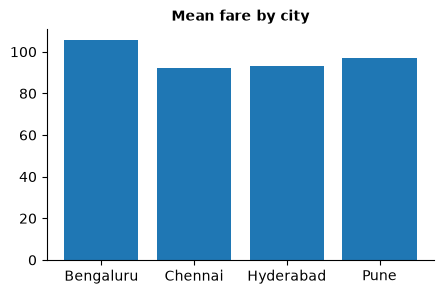

question 1 -> success after 2 attempt(s)
question 2 -> ASK THE USER after 3 attempt(s)


In [15]:
def generate_execute_repair(question, df, llm, max_tries=3):
    prompt = build_prompt(question, df)
    for attempt in range(1, max_tries + 1):
        code_str = llm(prompt)
        err = execute(code_str, df)
        if err is None:
            plt.show()
            return (code_str, attempt)
        else:
            plt.close("all")
            prompt = build_repair_prompt(question, df, err)
    return (None, max_tries)

code_ok, tries_ok = generate_execute_repair("average fare by city", df, fake_llm)
code_bad, tries_bad = generate_execute_repair("average customer happiness by city", df, fake_llm)
print("question 1 ->", "success" if code_ok else "failed", "after", tries_ok, "attempt(s)")
print("question 2 ->", "success" if code_bad else "ASK THE USER", "after", tries_bad, "attempt(s)")

assert code_ok is not None and tries_ok == 2, "the typo should be repaired on the second attempt"
assert code_bad is None and tries_bad == 3, "an invented column cannot be repaired: ask the user after 3 tries"

---
## Case 4 · Specs, not just code (Vega-Lite specs, validation, evaluation)
ChatViz can also return a **chart specification** (a Vega-Lite-style dictionary). The question was **"average fare by vehicle type in 2025, as a bar chart"**.
Four candidate specs came back from the LLM; one is correct.

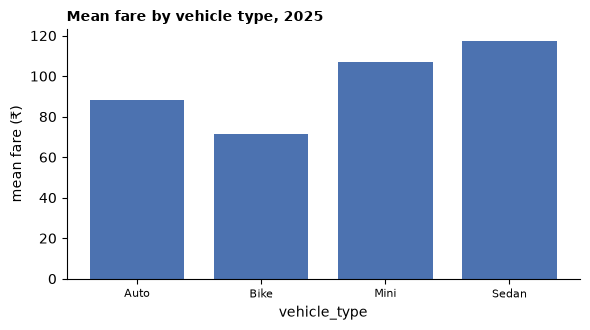

In [16]:
intent = {"aggregate": "mean", "filters": {"year": [2025]}}

good = {"title": "Mean fare by vehicle type, 2025", "transform": [{"filter": {"field": "year", "equal": 2025}}], "mark": "bar",
        "encoding": {"x": {"field": "vehicle_type", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}

import copy as _copy
B1 = _copy.deepcopy(good); B1["encoding"]["colour"] = {"field": "city", "type": "nominal"}                                     # key typo
B2 = _copy.deepcopy(good); B2["encoding"]["y"]["field"] = "fare_amount"                                                         # invented field
B3 = _copy.deepcopy(good); B3["encoding"]["shape"] = {"field": "wait_min", "type": "quantitative"}                              # wrong channel
B4 = _copy.deepcopy(good); B4["transform"] = []; B4["encoding"]["y"]["aggregate"] = "sum"                                       # wrong aggregate + filter dropped
specs = {"good": good, "B1": B1, "B2": B2, "B3": B3, "B4": B4}
render_spec(good, df); plt.tight_layout(); plt.show()

### 4a · Write two of the four validation checks
The **schema** and **field** checks are written for you. Write the **type–channel** check (shape must not encode a quantitative field; size must not encode a nominal field)
and the **sanity** check (compare the spec with the user's `intent`: aggregation and filters). Each returns a list of problem strings (empty list = pass).

In [17]:
import difflib
VALID_TOP = {"title", "data", "transform", "mark", "encoding"}
VALID_CH  = {"x", "y", "color", "shape", "size"}
VALID_KEYS = {"field", "type", "aggregate", "sort", "scale", "title", "condition", "value", "bin"}

def check_schema(spec):
    out = [f"unknown key '{k}'" for k in spec if k not in VALID_TOP]
    for ch, e in spec["encoding"].items():
        if ch not in VALID_CH:
            m = difflib.get_close_matches(ch, VALID_CH, 1)
            out.append(f"unknown channel '{ch}'" + (f" (did you mean '{m[0]}'?)" if m else ""))
    return out

def check_field(spec, df):
    used = [e["field"] for e in spec["encoding"].values() if isinstance(e, dict) and "field" in e]
    used += [t["filter"]["field"] for t in spec.get("transform", []) if "filter" in t]
    return [f"field '{f}' is not in the dataset" for f in used if f not in df.columns]

In [18]:
def check_type_channel(spec):
    problems = []
    for ch, e in spec["encoding"].items():
        if not isinstance(e, dict) or "type" not in e:
            continue
        if ch == "shape" and e["type"] == "quantitative":
            problems.append("channel 'shape' must not encode a quantitative field")
        if ch == "size" and e["type"] == "nominal":
            problems.append("channel 'size' must not encode a nominal field")
    return problems

def check_sanity(spec, intent):
    problems = []
    for ch in ("x", "y"):
        e = spec["encoding"].get(ch, {})
        if "aggregate" in e and e["aggregate"] != intent["aggregate"]:
            problems.append(f"{ch}-encoding aggregate '{e['aggregate']}' does not match intended '{intent['aggregate']}'")
    transforms = spec.get("transform", [])
    for field, values in intent.get("filters", {}).items():
        matched = False
        for t in transforms:
            f = t.get("filter", {})
            if f.get("field") == field:
                if len(values) == 1 and f.get("equal") == values[0]:
                    matched = True
                elif f.get("oneOf") == values:
                    matched = True
        if not matched:
            problems.append(f"missing or wrong filter on '{field}'")
    return problems

def validate(spec, df, intent):
    return {"1 schema": check_schema(spec), "2 field": check_field(spec, df),
            "3 type-channel": check_type_channel(spec), "4 sanity": check_sanity(spec, intent)}

report = pd.DataFrame({name: {k: ("pass" if not v else "; ".join(v)) for k, v in validate(sp, df, intent).items()} for name, sp in specs.items()}).T
display(report)

assert check_type_channel(good) == [] and len(check_type_channel(B3)) == 1
assert check_sanity(good, intent) == [] and len(check_sanity(B4, intent)) >= 2
assert check_type_channel(B1) == [] and check_sanity(B2, intent) == [], "each bad spec should be stopped by ITS check"

,1 schema,2 field,3 type-channel,4 sanity
good,pass,pass,pass,pass
B1,unknown channel 'colour' (did you mean 'color'?),pass,pass,pass
B2,pass,field 'fare_amount' is not in the dataset,pass,pass
B3,pass,pass,channel 'shape' must not encode a quantitative field,pass
B4,pass,pass,pass,y-encoding aggregate 'sum' does not match intended 'mean'; missing or wrong filter on ...


### 4b · Evaluate ChatViz on a benchmark
ChatViz was tested on 6 benchmark queries. The table records which **components** of its output matched the reference spec and whether the **plotted values** were right.
Compute: `exact_match` per query (all five components correct), the **exact-match rate**, the **execution accuracy** (values right), the **component accuracies**, and the list of queries that count for execution accuracy but **not** for exact match.

### Reflection: specifications and evaluation

10. Why should ChatViz validate a generated chart specification before executing it? Identify two checks that would improve reliability.

**Answer:** Validating catches mistakes before an analyst ever sees a wrong or misleading chart, since an LLM can produce a spec that "looks" plausible but references a field that doesn't exist or uses the wrong aggregate. The field check (do all referenced columns actually exist in the dataset) and the sanity check (does the spec's aggregation and filters match what the analyst actually asked for) both directly catch the kinds of silent errors seen in I1 and I3.

11. What evidence would convince you that ChatViz is ready for wider deployment? Propose three evaluation criteria, including at least one about correctness and one about user experience.

**Answer:** I would want to see (1) a high exact-match rate on a benchmark of real analyst questions, since that measures whether the full spec — not just the final numbers — is correct; (2) a low rate of unflagged validation failures in production logs, meaning most problems get caught before display; and (3) analyst-reported trust and task-completion time in a pilot, since a chart can be technically correct but still confuse or mislead a human reader.



In [19]:
T, F = True, False
ev = pd.DataFrame({"chart":        [T, T, F, T, T, F],
                   "x":            [T, T, T, T, T, T],
                   "y":            [T, T, T, T, T, T],
                   "aggregation":  [T, F, T, T, T, T],
                   "filter":       [T, T, T, F, T, T],
                   "values_right": [T, F, T, F, T, T]}, index=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"])
COMPONENTS = ["chart", "x", "y", "aggregation", "filter"]
ev

,chart,x,y,aggregation,filter,values_right
Q1,True,True,True,True,True,True
Q2,True,True,True,False,True,False
Q3,False,True,True,True,True,True
Q4,True,True,True,True,False,False
Q5,True,True,True,True,True,True
Q6,False,True,True,True,True,True


In [20]:
ev["exact_match"] = ev[COMPONENTS].all(axis=1)

exact_match_rate   = ev["exact_match"].mean()
execution_accuracy = ev["values_right"].mean()
component_acc      = {c: ev[c].mean() for c in COMPONENTS}
ea_not_em          = list(ev[ev["values_right"] & ~ev["exact_match"]].index)

print(exact_match_rate, execution_accuracy, component_acc, ea_not_em)

0.3333333333333333 0.6666666666666666 {'chart': np.float64(0.6666666666666666), 'x': np.float64(1.0), 'y': np.float64(1.0), 'aggregation': np.float64(0.8333333333333334), 'filter': np.float64(0.8333333333333334)} ['Q3', 'Q6']


---
## Case 5 · Editing the chart by talking to it (conversational chart editing, salience, titles)
An analyst asks ChatViz for *mean fare by city* and then edits it with four utterances. Each edit must be a **minimal patch** to the spec.

In [21]:
base = {"title": "Mean fare by city", "transform": [], "mark": "bar",
        "encoding": {"x": {"field": "city", "type": "nominal"},
                     "y": {"field": "fare", "aggregate": "mean", "type": "quantitative", "title": "mean fare (₹)"}}}
g = df.groupby("city")["fare"].mean()
focus_city = g.idxmax()
print("focus city:", focus_city, "| mean fare ₹%.0f vs ₹%.0f for the other cities on average" % (g.max(), g.drop(focus_city).mean()))

focus city: Bengaluru | mean fare ₹106 vs ₹94 for the other cities on average


### 5a · Four edits
Write the patches (start from a **deep copy** so `base` is never modified):
1. *"sort highest first"* → set `sort` to `"-y"` on the **x** encoding
2. *"make the bars horizontal"* → swap the `x` and `y` encodings
3. *"highlight the focus city in orange"* → set `encoding["color"]` to `{"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}`
4. *"add a title that says the point"* → a title that **asserts** the point and **names the focus city** (not "This chart shows …")

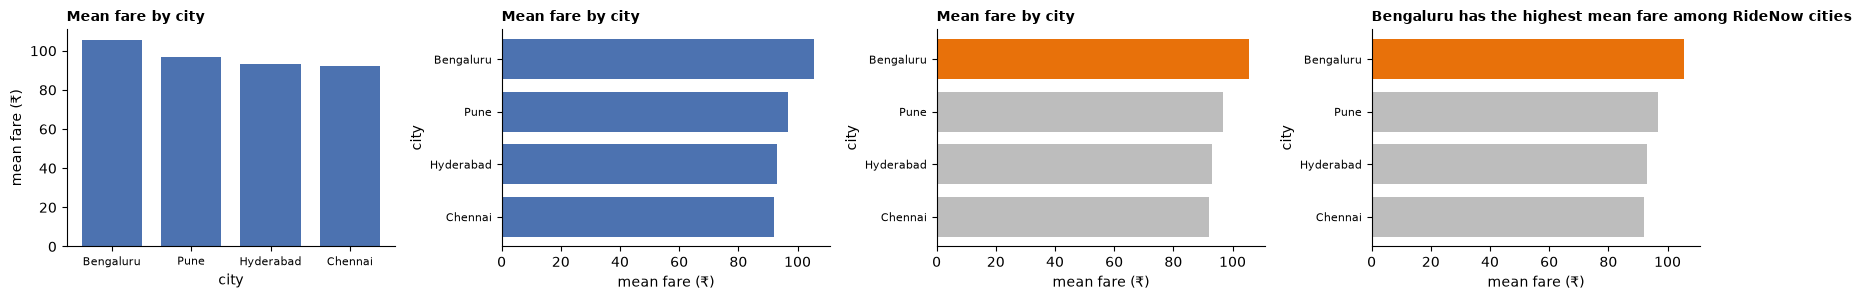

In [22]:
import copy

spec1 = copy.deepcopy(base)
spec1["encoding"]["x"]["sort"] = "-y"

spec2 = copy.deepcopy(spec1)
spec2["encoding"]["x"], spec2["encoding"]["y"] = spec2["encoding"]["y"], spec2["encoding"]["x"]

spec3 = copy.deepcopy(spec2)
spec3["encoding"]["color"] = {"condition": {"field": "city", "equal": focus_city, "value": ACCENT}, "value": GREY}

spec4 = copy.deepcopy(spec3)
spec4["title"] = f"{focus_city} has the highest mean fare among RideNow cities"

show_specs([spec1, spec2, spec3, spec4], df, ncols=4, w=4.3, h=3.1)

assert spec_diff(base, spec1) == ["encoding.x.sort"], "edit 1 must change only the sort"
assert spec_diff(spec1, spec2) != [] and spec2["encoding"]["x"]["field"] == "fare", "edit 2: x and y must be swapped"
assert spec_diff(spec2, spec3) and all(p.startswith("encoding.color") for p in spec_diff(spec2, spec3)), "edit 3 must only add the colour encoding"
assert spec_diff(spec3, spec4) == ["title"], "edit 4 must change only the title"
assert focus_city in spec4["title"] and lint_chart(spec4) == ["OK"], f"title problems: {lint_chart(spec4)}"

### 5b · Make the answer pop out
A second question: *"Which city has the lowest cancellation rate?"* ChatViz answers with a rainbow-coloured bar chart and no annotation.
Write `bar_colors(labels, answer)` so that **only the answer bar** gets the accent colour and every other bar is grey, and write a one-line **annotation** that states the answer in words.

### Reflection: conversational chart editing

12. Compare making a chart change through natural language with changing it through a traditional visual interface. What are the main benefits and risks of the conversational approach?

**Answer:** Natural language lets an analyst describe an intent quickly ("sort highest first", "highlight Bengaluru") without hunting through menus, which is faster for people who don't know the tool's UI well. The risk is that the system has to correctly interpret a loosely worded request into the right minimal patch, and a misread edit (e.g. swapping the wrong axis, or over-editing the spec) is less visible and harder to undo than clicking a button in a GUI, where the available actions are always visible.

13. If the user asks to ?make it clearer,? what additional information should ChatViz request before changing the chart? Suggest at least two possible interpretations.

**Answer:** "Make it clearer" is itself ambiguous, so ChatViz should ask what specifically feels unclear. Two reasonable interpretations are: (1) the visual design is cluttered or hard to read (suggesting fewer categories, bigger labels, or sorting), and (2) the point of the chart isn't obvious (suggesting an assertive title or a highlighted bar, as in 5a/5b). ChatViz could offer these as quick options rather than guessing.


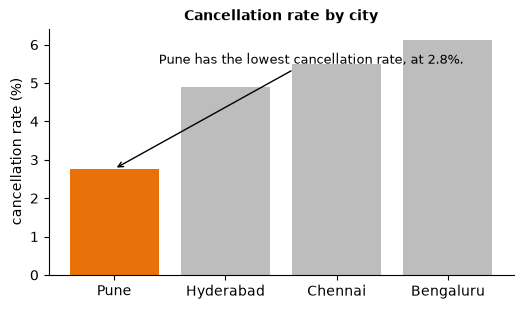

In [23]:
rate = df.groupby("city")["cancelled"].mean().sort_values() * 100
answer = rate.index[0]

def bar_colors(labels, answer):
    return [ACCENT if l == answer else GREY for l in labels]

annotation = f"{answer} has the lowest cancellation rate, at {rate.iloc[0]:.1f}%."

colors = bar_colors(list(rate.index), answer)
assert colors.count(ACCENT) == 1 and colors.count(GREY) == len(rate) - 1
assert answer in annotation, "name the answer city in the annotation"

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(rate.index, rate.values, color=colors)
ax.annotate(annotation, xy=(0, rate.iloc[0]), xytext=(0.4, rate.max() * 0.9), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set_ylabel("cancellation rate (%)"); ax.set_title("Cancellation rate by city")
plt.show()

---
## Case 6 · Post-mortem: what went wrong in the pilot? (benefits, failure modes, the nested model, mitigations)
Six incidents were reported during the pilot.

| # | Incident |
|---|---|
| I1 | The manager asked for *average* fare per city. The chart's title says "Average", but the bars are **totals**, so Bengaluru (most rides) wins. |
| I2 | After *"only 2025"*, the follow-up *"what about cancellations?"* was drawn for **all years**, with no warning. |
| I3 | A chart was drawn of `driver_score`, a column that **does not exist**; the tool quietly filled it with random numbers. |
| I4 | A **line** was drawn connecting Auto, Mini, Sedan and Bike for *"compare average fare by vehicle type"*. |
| I5 | Bars comparing cancellation rates of 4.1 % and 4.4 % started the y-axis at 4 %, making one city look **twice as bad**. |
| I6 | The caption under a scatter plot read *"Surge pricing **causes** cancellations."* |

### 6a · Classify
**(i)** Label each incident with exactly one failure mode from `FAILURE_MODES`.
**(ii)** Place each statement in the right level of **Munzner's nested model** (`"domain"`, `"abstraction"`, `"idiom"`, `"algorithm"`).
**(iii)** Pick the best **mitigation** for each situation from `MITIGATIONS`.

* **L1.** The code crashes with a `KeyError`.
* **L2.** The tool answers a *trend* question when the analyst actually needed to *compare two groups*.
* **L3.** A 12-slice pie is used to compare ride counts.
* **L4.** Finance defines "revenue" net of driver incentives, but the tool uses gross fares.

Mitigation situations: **M1** — follow-ups silently drop filters (I2). **M2** — the tool keeps choosing pies and truncated axes (I4/I5). **M3** — a wrong aggregation slips through while the chart runs fine (I1). **M4** — a chart is about to go into the **board report**.

In [24]:
FAILURE_MODES = ["hallucinated field", "wrong aggregation / filter", "wrong chart for the task", "misleading design", "context drift", "over-confident narrative"]
LEVELS = ["domain", "abstraction", "idiom", "algorithm"]
MITIGATIONS = ["echo the interpretation", "make choices editable", "validate before showing", "keep the spec / code", "constrain the design", "human review for decisions"]

In [25]:
failure_mode = {
    "I1": "wrong aggregation / filter",   # title says average, bars show totals
    "I2": "context drift",                # follow-up silently lost the 2025 filter
    "I3": "hallucinated field",           # driver_score doesn't exist, filled with random numbers
    "I4": "wrong chart for the task",     # line chart used for a categorical comparison
    "I5": "misleading design",            # truncated y-axis exaggerates the difference
    "I6": "over-confident narrative",     # caption claims causation from a scatter plot
}
nested_level = {
    "L1": "algorithm",     # a KeyError is an implementation/code-level crash
    "L2": "abstraction",   # picked the wrong abstract task (trend vs compare)
    "L3": "idiom",         # pie chart is the wrong visual idiom for this comparison
    "L4": "domain",        # disagreement about what "revenue" means in the business
}
mitigation = {
    "M1": "echo the interpretation",      # show which filters are still active so a silent drop is visible
    "M2": "constrain the design",         # rule out pies / truncated axes outright
    "M3": "validate before showing",      # catch wrong aggregation before the chart is shown
    "M4": "human review for decisions",   # high-stakes board report needs a human check
}

assert all(v in FAILURE_MODES for v in failure_mode.values()), "failure_mode: choose from FAILURE_MODES"
assert all(v in LEVELS for v in nested_level.values()), "nested_level: choose from LEVELS"
assert all(v in MITIGATIONS for v in mitigation.values()), "mitigation: choose from MITIGATIONS"

### 6b · Your recommendation
Incident **I1** looked perfectly fine on screen and was only noticed because a manager happened to check the numbers. In two or three sentences: **which level of the nested model do the costliest errors live at, why are they dangerous,
and what should SwiftBite-style rollout rules require before ChatViz goes to every analyst?** *(Use RideNow in your answer.)*

**Answer:** The costliest errors, like I1, live at the abstraction/algorithm boundary — the chart renders without any error and the title even looks right, but the underlying aggregation is wrong, so nothing in the interface signals a problem. These are dangerous precisely because they are invisible to someone just glancing at the chart, unlike a crash or an obviously bad chart type. Before ChatViz goes to every RideNow analyst, rollout rules should require that every generated spec pass the sanity check against the analyst's stated intent, and that any chart headed for a report or external audience get a mandatory human review rather than relying on someone happening to double-check the numbers.


### Reflection: rollout priorities and safeguards

14. What safeguards are needed when a visualization could expose sensitive operational information, such as driver performance or neighborhood-level demand?

**Answer:** ChatViz should enforce role-based access so an analyst can only query and chart data they're authorized to see, and should apply aggregation thresholds (e.g. refusing to show stats for a group below a minimum count) so individual drivers or small neighborhoods can't be singled out. Any export or share action on such a chart should also be logged, since sensitive operational data is more dangerous once it leaves the tool.

15. After auditing ChatViz, what is the single most important improvement you would prioritize, and why?

**Answer:** I would prioritize the validation step (schema, field, type-channel, and sanity checks) running automatically on every generated spec before it's shown, because the audit's most dangerous incidents (I1 and I3) were ones that looked completely normal on screen. A chart that crashes is obviously wrong and gets caught immediately; a chart that silently shows the wrong number is the one that actually misleads a business decision.


In [26]:
final_recommendation = (
    "Before ChatViz is rolled out to every RideNow analyst, require automatic validation "
    "(schema, field existence, type-channel, and sanity checks against stated intent) on "
    "every generated chart, plus mandatory human review for anything headed into a report "
    "or shared outside the team, since the pilot's costliest incidents were the ones that "
    "looked fine on screen but were quietly wrong underneath."
)